# Capítulo 3 · Actividad: limpieza de datos y outliers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/02_actividad_limpieza_outliers.ipynb)

Vas a aplicar lo que viste en la notebook de clase `04_limpieza_y_outliers` a **tres datasets distintos**. Cada uno tiene problemas diferentes, igual que en la vida real.

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```

### Cómo trabajar

- Cada ejercicio tiene una celda `# Tu código aquí`. Añade todas las celdas que necesites.
- En las celdas ✍️ **justifica tus decisiones**: en limpieza de datos casi nunca hay una única respuesta correcta, pero siempre tiene que haber un motivo.
- Al terminar, ejecuta **Kernel → Restart & Run All**.

| Parte | Datos | Tema |
|---|---|---|
| A. Empleados | una tabla pequeña creada en la notebook | Limpieza estructural e imputación |
| B. Pingüinos | `data/penguins.csv` | Valores faltantes |
| C. Viviendas de California | `data/california_housing.csv` | Outliers |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

---
## Parte A · Empleados 👩‍💼

Recursos Humanos te pasa esta tabla, exportada a mano de varias hojas de cálculo. Ejecuta la celda para crearla.

In [2]:
empleados = pd.DataFrame({
    "nombre": ["Ana", "Luis", "Marta", "Luis", "Pedro", "Sofía", "Juan", "Elena",
               "Diego", "Carla", "Raúl", "Elena", "Iván", "Lucía"],
    "departamento": [" ventas", "IT", "it ", "IT", "Ventas", "RRHH", "rrhh", "VENTAS",
                     "It", "ventas ", "IT", "VENTAS", "RRHH", " Rrhh"],
    "edad": [34, np.nan, 29, np.nan, 45, 38, np.nan, 41, 27, np.nan, 52, 41, 31, 36],
    "salario": ["$35,000", "$52,000", "$48,500", "$52,000", "39000", "$41,200", "$37,800",
                "40500", "$47,000", "$36,900", "$61,000", "40500", "$39,900", "$42,300"],
    "fecha_ingreso": ["2019-03-15", "2020-07-01", "2021-01-10", "2020-07-01", "2015-09-30",
                      "2018-11-05", "2022-02-14", "2016-06-20", "2023-04-03", "2021-08-16",
                      "2012-01-09", "2016-06-20", "2019-10-21", "2017-05-02"],
})
empleados

,nombre,departamento,edad,salario,fecha_ingreso
0,Ana,ventas,34.0,"$35,000",2019-03-15
1,Luis,IT,NaN,"$52,000",2020-07-01
2,Marta,it,29.0,"$48,500",2021-01-10
3,Luis,IT,NaN,"$52,000",2020-07-01
4,Pedro,Ventas,45.0,39000,2015-09-30
5,Sofía,RRHH,38.0,"$41,200",2018-11-05
6,Juan,rrhh,NaN,"$37,800",2022-02-14
7,Elena,VENTAS,41.0,40500,2016-06-20
8,Diego,It,27.0,"$47,000",2023-04-03
9,Carla,ventas,NaN,"$36,900",2021-08-16


### Ejercicio 1 · Diagnóstico

Haz el diagnóstico de calidad de `empleados`: tipos de cada columna, valores faltantes, filas duplicadas y cómo están escritas las categorías.

In [3]:
# tipos de datos
print("Tipos:")
print(empleados.dtypes, "\n")

# valores faltantes
print("Faltantes por columna:")
print(empleados.isna().sum(), "\n")

# filas duplicadas
print("Filas duplicadas:", empleados.duplicated().sum())
display(empleados[empleados.duplicated(keep=False)])

# cómo están escritas las categorías
print("\nValores de departamento:")
print(empleados["departamento"].map(repr).value_counts())

Tipos:
nombre               str
departamento         str
edad             float64
salario              str
fecha_ingreso        str
dtype: object 

Faltantes por columna:
nombre           0
departamento     0
edad             4
salario          0
fecha_ingreso    0
dtype: int64 

Filas duplicadas: 2


,nombre,departamento,edad,salario,fecha_ingreso
1,Luis,IT,NaN,"$52,000",2020-07-01
3,Luis,IT,NaN,"$52,000",2020-07-01
7,Elena,VENTAS,41.0,40500,2016-06-20
11,Elena,VENTAS,41.0,40500,2016-06-20



Valores de departamento:
departamento
'IT'         3
'RRHH'       2
'VENTAS'     2
' ventas'    1
'it '        1
'Ventas'     1
'rrhh'       1
'It'         1
'ventas '    1
' Rrhh'      1
Name: count, dtype: int64


✍️ **Pregunta:** haz una lista de todos los problemas que encontraste.

✍️ **Tu respuesta:** Problemas encontrados en `empleados`:
1. **Filas duplicadas:** 2 (Luis y Elena aparecen dos veces con exactamente los mismos datos).
2. **Categorías inconsistentes en `departamento`:** hay 10 escrituras distintas para solo 3 departamentos (`IT`, `it `, `It`, `RRHH`, `rrhh`, ` Rrhh`, `Ventas`, `VENTAS`, ` ventas`, `ventas `), por diferencias de mayúsculas y por espacios al inicio o al final.
3. **Valores faltantes:** 4 en `edad` (Luis aparece dos veces por el duplicado, así que son 3 empleados distintos: Luis, Juan y Carla).
4. **`salario` es texto** (`str`), no número; además tiene dos formatos distintos: `"$35,000"` (con `$` y coma) y `"39000"` (sin ellos).
5. **`fecha_ingreso` es texto**, no fecha, así que no se puede, por ejemplo, extraer el año ni ordenar por fecha.

### Ejercicio 2 · Duplicados

Elimina las filas duplicadas. ¿Cuántas filas quedan?

In [4]:
empleados = empleados.drop_duplicates().reset_index(drop=True)
print("Filas que quedan:", len(empleados))

Filas que quedan: 12


### Ejercicio 3 · Texto inconsistente

Normaliza `departamento` para que queden **exactamente tres** valores: `Ventas`, `IT` y `RRHH` (las siglas, en mayúsculas).

In [5]:
# quitamos espacios sobrantes y pasamos a mayúsculas; luego "VENTAS" -> "Ventas"
empleados["departamento"] = (
    empleados["departamento"].str.strip().str.upper().replace({"VENTAS": "Ventas"})
)
empleados["departamento"].value_counts()

departamento
Ventas    4
IT        4
RRHH      4
Name: count, dtype: int64

### Ejercicio 4 · Tipos de datos

a) Convierte `salario` a número. Ojo: no todos los valores tienen el mismo formato.

b) Convierte `fecha_ingreso` a fecha y crea la columna `año_ingreso`.

c) Comprueba los tipos con `dtypes`.

In [6]:
# a) salario: quitamos "$" y "," y convertimos a número (sirve para "$35,000" y para "39000")
empleados["salario"] = empleados["salario"].str.replace("[$,]", "", regex=True).astype(float)

# b) fecha y año de ingreso
empleados["fecha_ingreso"] = pd.to_datetime(empleados["fecha_ingreso"])
empleados["año_ingreso"] = empleados["fecha_ingreso"].dt.year

# c) comprobamos los tipos
empleados.dtypes

nombre                      str
departamento                str
edad                    float64
salario                 float64
fecha_ingreso    datetime64[us]
año_ingreso               int32
dtype: object

### Ejercicio 5 · Imputación

a) Crea una columna `edad_faltante` que indique qué empleados no tenían la edad.

b) Rellena la edad con la **mediana de su departamento**.

c) Comprueba que ya no quedan nulos y muestra la tabla final.

In [7]:
# a) marcamos quién no tenía la edad (antes de rellenar)
empleados["edad_faltante"] = empleados["edad"].isna()

# b) mediana de edad de cada departamento, para cada fila
mediana_depto = empleados.groupby("departamento")["edad"].transform("median")
empleados["edad"] = empleados["edad"].fillna(mediana_depto)

# c) ya no quedan nulos
print("Nulos en edad:", empleados["edad"].isna().sum())
empleados

Nulos en edad: 0


,nombre,departamento,edad,salario,fecha_ingreso,año_ingreso,edad_faltante
0,Ana,Ventas,34.0,35000.0,2019-03-15,2019,False
1,Luis,IT,29.0,52000.0,2020-07-01,2020,True
2,Marta,IT,29.0,48500.0,2021-01-10,2021,False
3,Pedro,Ventas,45.0,39000.0,2015-09-30,2015,False
4,Sofía,RRHH,38.0,41200.0,2018-11-05,2018,False
5,Juan,RRHH,36.0,37800.0,2022-02-14,2022,True
6,Elena,Ventas,41.0,40500.0,2016-06-20,2016,False
7,Diego,IT,27.0,47000.0,2023-04-03,2023,False
8,Carla,Ventas,41.0,36900.0,2021-08-16,2021,True
9,Raúl,IT,52.0,61000.0,2012-01-09,2012,False


✍️ **Pregunta:** ¿por qué la mediana del departamento y no la mediana de todos los empleados? ¿En qué caso daría igual?

✍️ **Tu respuesta:** Porque la edad depende del departamento y la mediana del departamento respeta esa diferencia. Aquí las medianas son distintas: **IT 29, Ventas 41 y RRHH 36**, mientras que la mediana de todos los empleados es 36. Si usáramos la global, a Luis (de IT, donde la mediana es 29) le pondríamos 36, un valor que no encaja con su grupo; con la de su departamento le ponemos 29. Y usamos la **mediana** y no la media porque no se deja arrastrar por valores extremos (como el empleado de 52 años).

Daría igual (o casi) si **la edad no tuviera relación con el departamento**, es decir, si todos los departamentos tuvieran más o menos la misma mediana; o en el caso extremo de que hubiera un solo departamento.

---
## Parte B · Pingüinos 🐧 (valores faltantes)

El archivo `data/penguins.csv` tiene medidas de 344 pingüinos de tres especies. Columnas: `species`, `island`, `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g` y `sex`.

### Ejercicio 6 · Diagnóstico de faltantes

a) Carga los datos en `pinguinos`.

b) Calcula cuántos valores faltan en cada columna y qué porcentaje representan.

c) Muestra las filas que tienen algún valor faltante.

In [8]:
# a) cargar los datos
pinguinos = pd.read_csv(DATA_DIR / "penguins.csv")

# b) cuántos valores faltan y qué porcentaje
faltantes = pd.DataFrame({
    "n_faltantes": pinguinos.isna().sum(),
    "porcentaje": (pinguinos.isna().mean() * 100).round(1),
})
display(faltantes)

# c) filas con algún valor faltante
pinguinos[pinguinos.isna().any(axis=1)]

,n_faltantes,porcentaje
species,0,0.0
island,0,0.0
bill_length_mm,2,0.6
bill_depth_mm,2,0.6
flipper_length_mm,2,0.6
body_mass_g,2,0.6
sex,11,3.2


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


✍️ **Pregunta:** ¿ves algún patrón en las filas con faltantes? ¿Faltan los datos de forma parecida en todas?

✍️ **Tu respuesta:** Los faltantes **no están repartidos de forma parecida**: `sex` es la columna con más (**11 valores, 3.2 %**), mientras que las cuatro medidas tienen solo **2 cada una (0.6 %)**. Patrones que se ven:
- Las **2 filas en las que faltan las cuatro medidas** (índices 3 y 339) son las mismas, y a ellas también les falta `sex`: son filas "vacías", de las que solo conocemos la especie y la isla.
- Las otras **9 filas** solo tienen incompleto el sexo (tienen todas las medidas).
- Los faltantes están en **Adelie (6) y Gentoo (5)**; en **Chinstrap no falta ninguno**. Eso sugiere que no son totalmente aleatorios (por ejemplo, pudo haber un problema al determinar el sexo en ciertos grupos de aves o en ciertas islas).

### Ejercicio 7 · Eliminar o imputar

Hay pingüinos a los que les faltan **todas** las medidas. Elimínalos y comprueba cuántas filas quedan.

In [9]:
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

# how="all": se elimina la fila solo si faltan TODAS las medidas
print("Filas antes:", len(pinguinos))
pinguinos = pinguinos.dropna(subset=medidas, how="all")
print("Filas después:", len(pinguinos))

Filas antes: 344
Filas después: 342


✍️ **Pregunta:** ¿por qué en este caso es mejor eliminar esas filas que imputarlas?

✍️ **Tu respuesta:** Porque de esas filas **no conocemos nada útil**: solo la especie y la isla; no hay ninguna medida (ni siquiera el sexo). Si las imputáramos, inventaríamos **las cuatro medidas completas** a partir de promedios de otros pingüinos, y esa fila no aportaría información real: solo añadiría "pingüinos promedio" idénticos que, además, achican artificialmente la variabilidad del dataset. Y el coste de eliminarlas es mínimo: se pierden solo **2 filas de 344 (0.6 %)**, quedando 342. Imputar tiene sentido cuando falta *una parte* de la fila y el resto ayuda a estimarla; aquí no queda nada con lo que estimarla.

### Ejercicio 8 · Dos estrategias para el sexo

Compara dos formas de rellenar `sex`, cada una en una **copia** de `pinguinos`:

a) Con la **moda**.

b) Con una categoría nueva, `"desconocido"`.

Muestra `value_counts()` del resultado en cada caso.

In [10]:
# a) con la moda
pinguinos_moda = pinguinos.copy()
pinguinos_moda["sex"] = pinguinos_moda["sex"].fillna(pinguinos_moda["sex"].mode()[0])
print("Con la moda:")
print(pinguinos_moda["sex"].value_counts(), "\n")

# b) con una categoría nueva
pinguinos_desconocido = pinguinos.copy()
pinguinos_desconocido["sex"] = pinguinos_desconocido["sex"].fillna("desconocido")
print("Con 'desconocido':")
print(pinguinos_desconocido["sex"].value_counts())

Con la moda:
sex
Male      177
Female    165
Name: count, dtype: int64 

Con 'desconocido':
sex
Male           168
Female         165
desconocido      9
Name: count, dtype: int64


✍️ **Pregunta:** ¿qué estrategia elegirías aquí y por qué? Fíjate en cuántos machos y hembras hay.

✍️ **Tu respuesta:** Elegiría **`"desconocido"`**. Tras el ejercicio 7 quedan 9 pingüinos sin sexo y el reparto real es casi 50/50: **168 machos y 165 hembras**. Con la moda, esos 9 pasan todos a macho (**177 machos frente a 165 hembras**) y creamos un desequilibrio que no existe en los datos: afirmamos que son machos sin tener ninguna prueba de ello, y solo por una diferencia mínima de 3 pingüinos. Con `"desconocido"` no inventamos nada y se queda visible que ese dato no se conoce.

El inconveniente es que aparece una tercera categoría que habrá que manejar después (por ejemplo, al codificar). Pero con solo 9 filas de 342 (2.6 %) el efecto es pequeño en cualquier caso, y es la opción más honesta.

### Ejercicio 9 · Con scikit-learn

Usa `SimpleImputer` para rellenar `sex` con el valor más frecuente. ¿Qué valor aprendió? ¿Coincide con la moda del ejercicio 8?

In [11]:
imputador = SimpleImputer(strategy="most_frequent")
sex_imputado = imputador.fit_transform(pinguinos[["sex"]])   # devuelve un array 2D

print("Valor aprendido:", imputador.statistics_)
print("Moda del ejercicio 8:", pinguinos["sex"].mode()[0])
print(pd.Series(sex_imputado.ravel()).value_counts())

Valor aprendido: ['Male']
Moda del ejercicio 8: Male
Male      177
Female    165
Name: count, dtype: int64


---
## Parte C · Viviendas de California 🏠 (outliers)

El archivo `data/california_housing.csv` viene del censo de California de 1990. **Cada fila es un distrito** (un barrio), no una vivienda:

| Columna | Significado |
|---|---|
| `MedInc` | ingreso mediano del distrito (en decenas de miles de $) |
| `HouseAge` | antigüedad mediana de las viviendas (años) |
| `AveRooms` | número medio de habitaciones por vivienda |
| `AveBedrms` | número medio de dormitorios por vivienda |
| `Population` | población del distrito |
| `AveOccup` | número medio de personas por vivienda |
| `Latitude`, `Longitude` | ubicación |
| `MedHouseVal` | valor mediano de las viviendas (en cientos de miles de $) |

### Ejercicio 10 · Primer vistazo

Carga los datos en `california` y muestra sus estadísticas descriptivas.

In [12]:
california = pd.read_csv(DATA_DIR / "california_housing.csv")
california.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


✍️ **Pregunta:** ¿en qué columnas el máximo está muy lejos del percentil 75%? ¿Te parece posible algún valor?

✍️ **Tu respuesta:** El máximo está muy lejos del percentil 75 % en cuatro columnas:
- `AveRooms`: p75 = 6.05 y máximo = **141.91** habitaciones por vivienda.
- `AveBedrms`: p75 = 1.10 y máximo = **34.07**.
- `Population`: p75 = 1725 y máximo = **35 682** (esta sí es posible: un distrito muy grande).
- `AveOccup`: p75 = 3.28 y máximo = **1243.33** personas por vivienda.

Los valores de `AveRooms`, `AveBedrms` y sobre todo `AveOccup` **no parecen posibles** como promedio de viviendas normales: no existen casas con 141 habitaciones ni 1243 personas por vivienda. Probablemente son distritos con muy pocas viviendas y mucha población que no vive en casas normales (residencias, cárceles, hoteles...) o errores en los datos. (`MedInc` con máximo 15 y `MedHouseVal` con máximo 5 son valores topados por el censo, no errores.)

### Ejercicio 11 · Detección visual

Dibuja en una misma figura el boxplot de `AveRooms`, `AveOccup` y `Population`, cada uno en su propio gráfico.

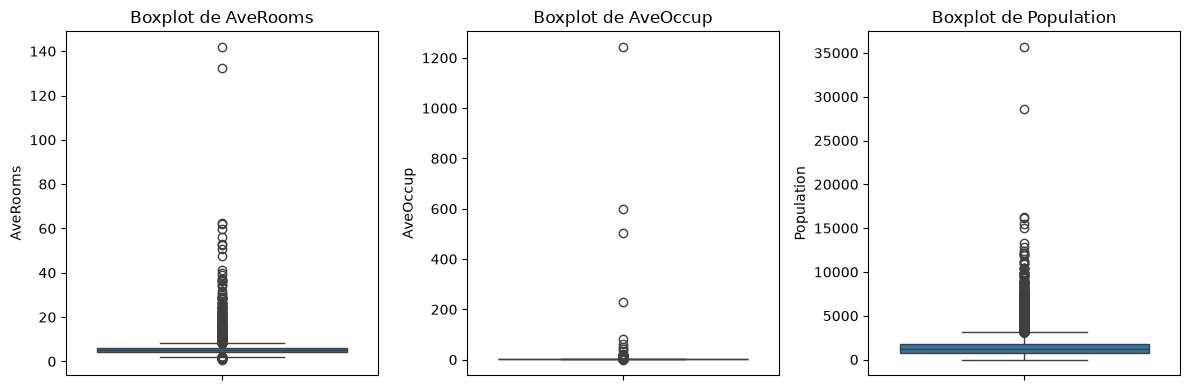

In [13]:
columnas = ["AveRooms", "AveOccup", "Population"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, columnas):
    sns.boxplot(y=california[col], ax=ax)
    ax.set_title(f"Boxplot de {col}")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

### Ejercicio 12 · Z-score contra IQR

Para **cada columna** de `california`, cuenta cuántos outliers detecta el z-score ($|z| > 3$) y cuántos el IQR. Junta los resultados en un DataFrame con una fila por columna.

In [14]:
filas = {}
for col in california.columns:
    datos = california[col]

    # z-score: cuántas desviaciones estándar se aleja de la media
    z = (datos - datos.mean()) / datos.std()
    n_z = (z.abs() > 3).sum()

    # IQR: fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
    q1, q3 = datos.quantile([0.25, 0.75])
    iqr = q3 - q1
    n_iqr = ((datos < q1 - 1.5 * iqr) | (datos > q3 + 1.5 * iqr)).sum()

    filas[col] = {"z_score": n_z, "iqr": n_iqr}

outliers = pd.DataFrame(filas).T
outliers

,z_score,iqr
MedInc,345,681
HouseAge,0,0
AveRooms,133,511
AveBedrms,145,1424
Population,342,1196
AveOccup,8,711
Latitude,0,0
Longitude,0,0
MedHouseVal,0,1071


✍️ **Pregunta:** en `AveOccup`, ¿por qué el z-score detecta tan pocos outliers y el IQR tantos? ¿Cuál de los dos números te parece más razonable?

✍️ **Tu respuesta:** Porque los valores extremos **inflan la media y la desviación estándar** con las que se calcula el z-score. En `AveOccup` la desviación estándar es 10.39 (con una media de 3.07), pero los datos típicos están entre 2.43 y 3.28. Para tener |z| > 3 un distrito necesita pasar de unas 34 personas por vivienda (3.07 + 3 × 10.39), así que solo salen **8**: los outliers esconden a los demás (*enmascaramiento*). El IQR usa cuartiles, que no se ven afectados por los extremos: su rango es de solo ~0.85, así que el límite superior queda en ~4.5 personas por vivienda y marca **711** distritos.

¿Cuál es más razonable? Ninguno por sí solo. Los 8 del z-score son claramente errores o casos absurdos. Los 711 del IQR (3.4 % de los distritos) incluyen muchos valores perfectamente posibles (5, 6 o 7 personas por vivienda en zonas con familias grandes o pisos compartidos), así que **eliminarlos todos sería excesivo**. Por eso lo mejor es usar el IQR para *revisar* y decidir con un criterio de negocio (ejercicio siguiente).

### Ejercicio 13 · Criterio de negocio

`AveOccup` es el número medio de personas que viven en cada vivienda del distrito.

a) Muestra los 5 distritos con mayor `AveOccup`.

b) Decide un **umbral razonable** por encima del cual el valor no tiene sentido, y elimina esos distritos. ¿Cuántos eliminaste?

In [15]:
# a) los 5 distritos con más personas por vivienda
display(california.nlargest(5, "AveOccup"))

# b) umbral razonable: más de 10 personas por vivienda en promedio no tiene sentido
umbral = 10
antes = len(california)
california_limpio = california[california["AveOccup"] <= umbral]
print(f"Eliminados: {antes - len(california_limpio)} distritos (quedan {len(california_limpio)})")

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
19006,10.2264,45.0,3.166667,0.833333,7460.0,1243.333333,38.32,-121.98,1.375
3364,5.5179,36.0,5.142857,1.142857,4198.0,599.714286,40.41,-120.51,0.675
16669,4.2639,46.0,9.076923,1.307692,6532.0,502.461538,35.32,-120.70,3.500
13034,6.1359,52.0,8.275862,1.517241,6675.0,230.172414,38.69,-121.15,2.250
9172,4.2391,5.0,5.123810,0.933333,8733.0,83.171429,34.47,-118.59,1.546


Eliminados: 37 distritos (quedan 20603)


✍️ **Pregunta:** ¿qué umbral elegiste y por qué?

✍️ **Tu respuesta:** Elegí **10 personas por vivienda**. Los 5 valores mayores son 1243, 599, 502, 230 y 83, imposibles para viviendas normales. Aun con familias muy grandes o pisos compartidos, que **el promedio de un distrito completo** pase de 10 personas por casa no es creíble, mientras que valores entre 5 y 10 sí pueden darse. Con ese umbral eliminé **37 distritos** (el 0.18 % del total, quedan 20 603), así que apenas perdemos datos y quitamos solo lo que claramente no tiene sentido. Otro umbral cercano (8, 12, 15...) también sería defendible si se justifica; lo importante es que el corte venga de un criterio sobre lo que es posible y no de una fórmula.

### Ejercicio 14 · Winsorización

Winsoriza `AveRooms` en los percentiles 1 y 99, guardando el resultado en una columna nueva `AveRooms_wins`. Compara las estadísticas descriptivas de las dos columnas.

In [16]:
# percentiles 1 y 99 de AveRooms
p1, p99 = california["AveRooms"].quantile([0.01, 0.99])
print(f"Percentil 1: {p1:.2f} | Percentil 99: {p99:.2f}")

# clip: lo que está por debajo de p1 se sube a p1, lo que está por encima de p99 se baja a p99
california["AveRooms_wins"] = california["AveRooms"].clip(lower=p1, upper=p99)

california[["AveRooms", "AveRooms_wins"]].describe().round(2)

Percentil 1: 2.58 | Percentil 99: 10.36


,AveRooms,AveRooms_wins
count,20640.00,20640.00
mean,5.43,5.33
std,2.47,1.32
min,0.85,2.58
25%,4.44,4.44
50%,5.23,5.23
75%,6.05,6.05
max,141.91,10.36


### Ejercicio 15 · Un caso raro

Muestra los 5 valores más frecuentes de `MedHouseVal`.

In [17]:
california["MedHouseVal"].value_counts().head(5)

MedHouseVal
5.00001    965
1.37500    122
1.62500    117
1.12500    103
1.87500     93
Name: count, dtype: int64

✍️ **Pregunta:** ¿qué crees que pasó con el valor más repetido? ¿Es un outlier? ¿Qué problema podría causarle a un modelo que intente predecir el valor de las viviendas?

✍️ **Tu respuesta:** El valor **5.00001** (es decir, $500 001) aparece **965 veces** (el 4.7 % de los distritos), muy por encima del segundo más repetido (1.375, con 122). Lo que pasó es que el censo **topó (censuró) el valor en $500 001**: cualquier distrito que valiera más se registró con ese tope.

**No es un outlier en el sentido de un error o un valor extremo aislado**: es un "muro" en el que se acumulan distritos cuyo valor real es mayor, pero que desconocemos. Un modelo que prediga el valor de las viviendas tendría problemas: aprendería que el valor **nunca supera ese tope** y **subestimaría** sistemáticamente los distritos caros; además, la relación con variables como el ingreso se aplanaría artificialmente en la parte alta. Hay que tenerlo en cuenta (por ejemplo, quitar esos distritos reconociendo que el modelo no valdrá para las zonas más caras, o usar un método que trate los datos censurados).